In [1]:
# !git clone https://github.com/febse/ta2025.git repo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfTransformer

import sys
from pathlib import Path

try:
    from animations import *
except ImportError:
    try:
        # Running from the class/ folder: the animations package is in the repository root
        sys.path.append(str(Path.cwd().parent))
        from animations import *
    except ImportError:
        # Running in Colab after cloning the repository into ./repo
        from repo.animations import *

np.set_printoptions(precision=3, suppress=True)

# The Linear Algebra Behind the Singular Value Decomposition


<https://www.desmos.com/3d/9qwtmlypx2>


## Warm-up: structure and noise in a point cloud

Before turning to text, we look at the SVD on a matrix that is easy to see. Four points form the outline of a house in the $x$-$y$ plane (the **structure**). The third coordinate $z$ contains only **noise**.

The data matrix has one row per point and one column per coordinate: $P \in \mathbb{R}^{4 \times 3}$.

In [17]:
np.random.seed(424)

house_xy = np.array([
    [0.0, 0.0],  # bottom left
    [2.0, 0.0],  # bottom right
    [2.0, 2.0],  # top right
    [0.0, 2.0],  # top left
])
house_xy = house_xy - house_xy.mean(axis=0)  # center the points

standard_noise = np.random.normal(size=house_xy.shape[0])
noise_scale = 0.5

house = np.column_stack([house_xy, noise_scale * standard_noise])
print("Shape of the house matrix (points x coordinates):", house.shape)

Shape of the house matrix (points x coordinates): (4, 3)


In [18]:
house

array([[-1.   , -1.   , -0.074],
       [ 1.   , -1.   ,  0.668],
       [ 1.   ,  1.   ,  0.062],
       [-1.   ,  1.   , -0.849]])

### SVD of the house

The right singular vectors (rows of $V^\top$) are the new axes. The first two should span (almost) the $x$-$y$ plane, and the third one should be close to the $z$ axis, which carries only noise.

In [20]:
U_house, S_house, VT_house = np.linalg.svd(house, full_matrices=False)

print("Singular values:", S_house)
print("V^T (rows = directions, columns = x, y, z):\n", VT_house)

print("U", U_house)

Singular values: [2.272 2.    0.113]
V^T (rows = directions, columns = x, y, z):
 [[ 0.675 -0.564  0.475]
 [ 0.641  0.767  0.   ]
 [-0.365  0.305  0.88 ]]
U [[-0.064 -0.704 -0.042]
 [ 0.685 -0.063 -0.724]
 [ 0.062  0.704 -0.046]
 [-0.723  0.063 -0.687]]


In [4]:
house_reconstructed = U_house @ np.diag(S_house) @ VT_house
print("House matrix P (x, y, z):\n", house.round(3))
print("U Sigma V^T:\n", house_reconstructed.round(3))
print("Reconstruction equals P:", np.allclose(house, house_reconstructed))

House matrix P (x, y, z):
 [[-1.    -1.     0.099]
 [ 1.    -1.    -0.028]
 [ 1.     1.     0.13 ]
 [-1.     1.     0.305]]
U Sigma V^T:
 [[-1.    -1.     0.099]
 [ 1.    -1.    -0.028]
 [ 1.     1.     0.13 ]
 [-1.     1.     0.305]]
Reconstruction equals P: True


In [14]:
house

array([[-1.   , -1.   ,  0.099],
       [ 1.   , -1.   , -0.028],
       [ 1.   ,  1.   ,  0.13 ],
       [-1.   ,  1.   ,  0.305]])

### Truncated SVD: keep two layers

Keeping only the first $k = 2$ layers replaces every point by its projection on the plane spanned by $v_1$ and $v_2$:

$$
P_2 = \sigma_1 u_1 v_1^\top + \sigma_2 u_2 v_2^\top .
$$

In [23]:
house_rank2

array([[-1.002, -0.999, -0.069],
       [ 0.97 , -0.975,  0.74 ],
       [ 0.998,  1.002,  0.067],
       [-1.028,  1.024, -0.781]])

ValueError: 'middle' is not a valid value for loc; supported values are 'best', 'upper right', 'upper left', 'lower left', 'lower right', 'right', 'center left', 'center right', 'lower center', 'upper center', 'center'

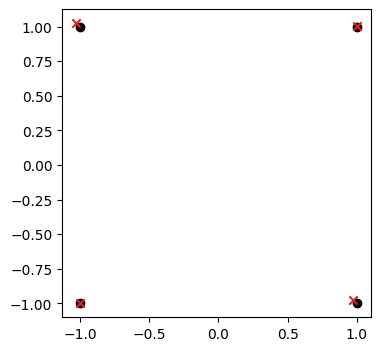

In [ ]:
def truncated_reconstruction(U, S, VT, k):
    return U[:, :k] @ np.diag(S[:k]) @ VT[:k, :]

house_rank2 = truncated_reconstruction(U_house, S_house, VT_house, k=2)

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(house_xy[:, 0], house_xy[:, 1], color="black", label="true structure")
ax.scatter(house_rank2[:, 0], house_rank2[:, 1], color="tab:red", marker="x", label="rank-2 SVD (x, y)")
ax.set_aspect("equal")
ax.legend(loc="center")
ax.set_title("Rank-2 reconstruction, small noise")
plt.show()

### When the noise is larger than the structure

The singular values measure how much of the total "size" each direction carries. The noise adds $\sigma_z \cdot \text{(standard normal)}$ to the $z$ column. If the noise is large enough, the $z$ direction carries more than the house, and the **largest** singular value flips to the noise direction.

In [6]:
rows = []
for scale in [0.2, 0.5, 1.0, 2.0, 4.0]:
    noisy_house = np.column_stack([house_xy, scale * standard_noise])
    singular_values_noisy = np.linalg.svd(noisy_house, compute_uv=False)
    rows.append({"noise scale": scale, "sigma_1": singular_values_noisy[0],
                 "sigma_2": singular_values_noisy[1], "sigma_3": singular_values_noisy[2]})

pd.DataFrame(rows).round(3)

,noise scale,sigma_1,sigma_2,sigma_3
0,0.2,2.014,2.0,0.252
1,0.5,2.094,2.0,0.607
2,1.0,2.432,2.0,1.045
3,2.0,3.769,2.0,1.348
4,4.0,7.072,2.0,1.437


In [7]:
very_noisy_house = np.column_stack([house_xy, 4.0 * standard_noise])
U_noisy, S_noisy, VT_noisy = np.linalg.svd(very_noisy_house, full_matrices=False)

print("Singular values:", S_noisy)
print("First right singular vector v1 (x, y, z):", VT_noisy[0].round(3))

Singular values: [7.072 2.    1.437]
First right singular vector v1 (x, y, z): [ 0.129 -0.154 -0.98 ]


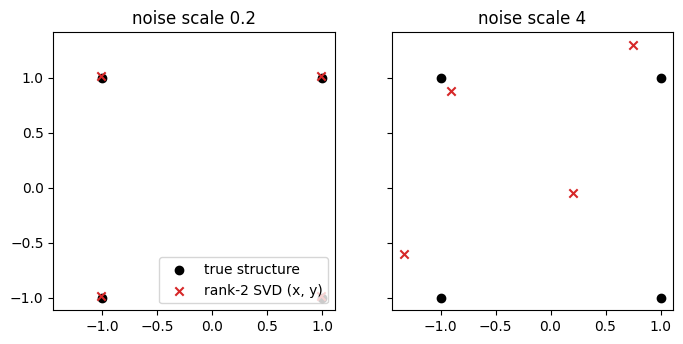

In [8]:
house_noisy_rank2 = truncated_reconstruction(U_noisy, S_noisy, VT_noisy, k=2)

fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)
for ax, reconstruction, title in zip(
    axes, [house_rank2, house_noisy_rank2], ["noise scale 0.2", "noise scale 4"]
):
    ax.scatter(house_xy[:, 0], house_xy[:, 1], color="black", label="true structure")
    ax.scatter(reconstruction[:, 0], reconstruction[:, 1], color="tab:red", marker="x", label="rank-2 SVD (x, y)")
    ax.set_aspect("equal")
    ax.set_title(title)
axes[0].legend(loc="lower right")
plt.show()

With strong noise, the first layer describes the noise in $z$, so the rank-2 reconstruction no longer recovers the house. The SVD ranks directions by variability, not by meaning: whether the top layers contain *structure* depends on the signal-to-noise ratio.

## The Derivation

The eigenvalues decomposition works for any square matrix $A \in \mathbb{R}^{n \times n}$. Fro symmetric matrices, the eigenvectors are orthogonal and the eigenvalues are real. The SVD generalizes this to rectangular matrices $X \in \mathbb{R}^{n \times m}$.

It works on the the fact that $X^{T} X$ and $X X^{T}$ are symmetric and positive semi-definite so they have orthogonal eigenvectors and non-negative eigenvalues (though some will be zero).

EVD applied to $X^{T} X$ gives the right singular vectors $v_i$ and the singular values $\sigma_i^2$. EVD applied to $X X^{T}$ gives the left singular vectors $u_i$ and the same singular values $\sigma_i^2$. The SVD is a way to combine these two EVDs into one decomposition.

## The TF-IDF Matrix

Let a corpus have $n$ documents and a vocabulary of $m$ words. The **TF-IDF matrix** $X$ has

- one **row** per document ($n$ rows),
- one **column** per word ($m$ columns),
- entry $X_{dw}$ = the TF-IDF weight of word $w$ in document $d$.

$$
X \in \mathbb{R}^{n \times m}
$$

Two ways to read $X$:

- A **row** is a document, described by $m$ (one per word) numbers: documents are embedded in *word space* $\mathbb{R}^m$.
- A **column** is a word, described by $n$ numbers (one per document): words live in *document space* $\mathbb{R}^n$.


## A small example: four documents, three words

In [9]:
words = ["data", "model", "rare"]
documents = ["doc1", "doc2", "doc3", "doc4"]

counts = np.array([
    [2, 1, 0],
    [1, 2, 0],
    [1, 0, 0],
    [1, 0, 3],
])

X = pd.DataFrame(counts, index=documents, columns=words)
X

,data,model,rare
doc1,2,1,0
doc2,1,2,0
doc3,1,0,0
doc4,1,0,3


## The Word-Similarity Matrix

The example count matrix above holds the number of occurrences of each word in each document (without IDF weighting). When we build the $X^T X$ matrix we are computing the dot product of each pair of word vectors (in document space). As the dot product measures similarity, the $X^T X$ matrix is a word-word similarity matrix. It will have zero entries for pairs of words that never occur together in any document (i.e. occur in different documents).

In [10]:
X.T @ X

,data,model,rare
data,7,4,3
model,4,5,0
rare,3,0,9


## The Documents-Similarity Matrix

The other side of the SVD is the application of EVD to $X X^T$. Just as words lived in document space, documents live in word space and the matrix product $X X^T$ is a document-document similarity matrix (as measured by word overlap). The matrix will have zero entries for pairs of documents that never share a word.

In [11]:
X @ X.T

,doc1,doc2,doc3,doc4
doc1,5,4,2,2
doc2,4,5,1,1
doc3,2,1,1,1
doc4,2,1,1,10


## Scoring Documents on Directions in Word Space

Documents are points in word space (here with 3 dimensions, one for each word). Consider scoring a document on a direction $v$ in word space and take for example the direction $v = (1, 0, 0)$ corresponding to the word `data`. The score of a document $d$ on this direction is the dot product of the document vector $x_d$ with $v$:

The vector describing the document "data" is $x_d = (1, 0, 0)$, so the score is

$$
x_d \cdot v = (1, 0, 0) \cdot (1, 0, 0) = 1
$$

What we understand under _importance_ of a score is its (Euclidean) length _norm_ (remember the LIVE EVIL rule when computing transposes):

$$
\|x_d \cdot v\|^2 = (x_d v)^{T} (x_d v) = v^T x_d^T x_d v
$$

Now consider scoring every document on some direction $v$ in word space. We need to compute the dot product of every document vector $x_d$ with $v$ and this is exactly what matrix multiplication does: $X v$ is a vector of scores, one per document.

Now consider the importance of the scores (their sum of squares). This is the squared norm of the vector $X v$:
$$
\|X v\|^2 = (X v)^{T} (X v) = v^T X^T X v
$$

Now substitute with the EVD of $X^T X$:

$$
\|X v\|^2 = v^T X^T X v = v^T V \Sigma^2 V^T v
$$

If $v$ is, say the first right singular vector $v_1$, then its dot product with the other right singular vectors is zero except for itself, and we get

$$
\|X v_1\|^2 = v_1^T V \Sigma^2 V^T v_1 = \sigma_1^2
$$

In [12]:
# Score every document along the "data" direction, v = (1, 0, 0)
data_direction = np.array([1.0, 0.0, 0.0])
document_scores = X.to_numpy() @ data_direction

print("Scores along the data direction:", document_scores)
print("doc3 score:", document_scores[2])
print("Sum of squared scores:", np.linalg.norm(document_scores) ** 2)
print(
    "Quadratic form v^T X^T X v:",
    data_direction @ (X.to_numpy().T @ X.to_numpy()) @ data_direction,
)

# Score documents along the first right singular vector
first_singular_direction = V[:, 0]
first_direction_scores = X.to_numpy() @ first_singular_direction

print("\nSquared score norm along v1:", np.linalg.norm(first_direction_scores) ** 2)
print("Largest singular value squared:", singular_values[0] ** 2)

Scores along the data direction: [2. 1. 1. 1.]
doc3 score: 1.0
Sum of squared scores: 7.000000000000001
Quadratic form v^T X^T X v: 7.0


NameError: name 'V' is not defined

## Combining the two EVDs 

We have two EDV decompositions:

Left singular vectors (documents):

$$
X X^T = U \Sigma^2 U^T
$$


Right singular vectors (words):

$$
X^T X = V \Sigma^2 V^T
$$

These two decompositions can be combined into a single decomposition of $X$ itself:

$$
X  = U \Sigma V^T
$$

where the singular values $\sigma_i$ are the square roots of the eigenvalues of $X^T X$ and $X X^T$. The singular values matrix is diagonal, so taking the square root simply means applying it to each diagonal entry.


In [ ]:
# eigh is for symmetric matrices; it returns eigenvalues in ascending order
eigenvalues_words, V = np.linalg.eigh(X.T @ X)

# Reorder from the largest to the smallest eigenvalue
order = np.argsort(eigenvalues_words)[::-1]
eigenvalues_words = eigenvalues_words[order]
V = V[:, order]

singular_values = np.sqrt(eigenvalues_words)

print("Eigenvalues", eigenvalues_words)
print("Left singular values:", singular_values)
print("Shape:", V.shape)
print("V:", V)
print("V^T V =\n", (V.T @ V).round(3))

Eigenvalues [12.125  7.487  1.388]
Left singular values: [3.482 2.736 1.178]
Shape: (3, 3)
V: [[ 0.669 -0.365 -0.648]
 [ 0.375 -0.587  0.718]
 [ 0.642  0.723  0.255]]
V^T V =
 [[ 1. -0. -0.]
 [-0.  1. -0.]
 [-0. -0.  1.]]


In [ ]:
# The same for X X^T (n x n). Separate names, so the word results above stay intact
eigenvalues_documents, U_full = np.linalg.eigh(X @ X.T)

order = np.argsort(eigenvalues_documents)[::-1]
eigenvalues_documents = eigenvalues_documents[order]
U_full = U_full[:, order]

print("Eigenvalues", eigenvalues_documents)
print("Shape:", U_full.shape, "(the last eigenvalue is 0: rank(X) <= 3)")
print("U_full:\n", U_full.round(3))
print("U^T U =\n", (U_full.T @ U_full).round(3))

Eigenvalues [12.125  7.487  1.388  0.   ]
Shape: (4, 4) (the last eigenvalue is 0: rank(X) <= 3)
U_full:
 [[-0.492 -0.481  0.491  0.535]
 [-0.408 -0.562 -0.668 -0.267]
 [-0.192 -0.133  0.55  -0.802]
 [-0.745  0.659 -0.1    0.   ]]
U^T U =
 [[ 1.  0.  0.  0.]
 [ 0.  1. -0. -0.]
 [ 0. -0.  1.  0.]
 [ 0. -0.  0.  1.]]


## EVD of $X^\top X$: Word Similarity as a Sum over Topics

**Assumptions.** $X \in \mathbb{R}^{n \times m}$ has one row per document and one column per word. The entry of the word-word matrix is the dot product of two word vectors in document space:

$$
(X^\top X)_{ab} = \sum_{d=1}^{n} X_{da} X_{db} = x_a^\top x_b .
$$

**Fact.** $X^\top X$ is symmetric and positive semi-definite, since $w^\top X^\top X w = \|Xw\|^2 \ge 0$. Hence its eigenvalues are real and non-negative and its eigenvectors can be chosen orthonormal:

$$
X^\top X = V \Lambda V^\top, \qquad \Lambda = \mathrm{diag}(\lambda_1 \ge \dots \ge \lambda_m \ge 0), \qquad \lambda_j = \sigma_j^2 .
$$

**Meaning of the eigenvectors.** For a unit vector $v_j$,

$$
\lambda_j = v_j^\top X^\top X v_j = \|X v_j\|^2 ,
$$

the squared length of the document scores along $v_j$. The first eigenvector $v_1$ maximizes $\|Xw\|^2$ over all unit vectors $w$. The second does the same among directions orthogonal to $v_1$, and so on. Words with large entries of the same sign in $v_j$ occur together in the same documents; opposite signs mean the words trade off. Each $v_j$ is a *topic*: a weighting of the vocabulary.

**Word similarity as a sum over topics.** Writing out the product gives

$$
(X^\top X)_{ab} = \sum_{j=1}^{r} \sigma_j^2 \, v_{aj} \, v_{bj} .
$$

Two words are similar when they load on the same topics with the same sign. Keeping only the first $k$ terms gives a smoothed similarity based on shared topics instead of exact co-occurrence.

**Caveats.**

- The eigenvalues are $\sigma_j^2$, not $\sigma_j$. Shares of "energy" use $\sigma_j^2 / \sum_i \sigma_i^2$.
- Equal (or nearly equal) eigenvalues leave the eigenvectors defined only up to a rotation within their span.
- $X$ is not mean-centered here, so $v_1$ mostly reflects overall word frequency. With centered columns, $X^\top X$ is proportional to the covariance matrix and the decomposition is PCA.
- The signs of $v_j$ are arbitrary (see the sign matching of $u_j$ and $v_j$ below).

In [ ]:
word_similarity = (X.T @ X).to_numpy()

# Topic j contributes sigma_j^2 * v_j v_j^T (a rank-1 matrix); the topics add up to X^T X
topic_contributions = [eigenvalues_words[j] * np.outer(V[:, j], V[:, j]) for j in range(len(words))]
print("Sum of topics equals X^T X:", np.allclose(sum(topic_contributions), word_similarity))

# Loadings of each word on each topic (columns of V)
display(pd.DataFrame(V, index=words, columns=["topic 1", "topic 2", "topic 3"]).round(3))

# Share of the total energy captured by each topic: sigma_j^2 / sum_i sigma_i^2
print("Energy share per topic:", (eigenvalues_words / eigenvalues_words.sum()).round(3))

# Smoothed word similarity from the first topic only
pd.DataFrame(topic_contributions[0], index=words, columns=words).round(2)

In [ ]:
# Combine the two eigendecompositions: Sigma is n x m = 4 x 3

Sigma_full = np.zeros(X.shape)
np.fill_diagonal(Sigma_full, singular_values)

# Match the signs of u_j to v_j, so that X v_j = sigma_j u_j
X_values = X.to_numpy()
sign_flips = np.sign(np.sum(U_full[:, :3] * (X_values @ V), axis=0))
U_full[:, :3] = U_full[:, :3] * sign_flips

print("U_full:", U_full.shape, " Sigma:", Sigma_full.shape, " V^T:", V.T.shape)
print("X == U Sigma V^T:", np.allclose(X_values, U_full @ Sigma_full @ V.T))

U_full @ Sigma_full @ V.T

U_full: (4, 4)  Sigma: (4, 3)  V^T: (3, 3)
X == U Sigma V^T: True


array([[ 2.,  1.,  0.],
       [ 1.,  2.,  0.],
       [ 1.,  0.,  0.],
       [ 1., -0.,  3.]])

In [ ]:
# Left singular vectors from the right ones: u_j = X v_j / sigma_j  (n x 1 each)
U = X.to_numpy() @ V / singular_values

print("U shape:", U.shape)
print("U^T U =\n", (U.T @ U).round(3))

U shape: (4, 3)
U^T U =
 [[ 1. -0. -0.]
 [-0.  1.  0.]
 [-0.  0.  1.]]


## Putting it together: $X = U \Sigma V^\top$

Since $X v_j = \sigma_j u_j$ for all $j$, in matrix form $XV = U\Sigma$. Multiplying from the right by $V^\top$ (and using $VV^\top = I$):

$$
X = U \Sigma V^\top
$$

| matrix | dimensions (here) | contents |
|--------|------------------|----------|
| $U$ | $n \times r$ = $4 \times 3$ | left singular vectors (documents), one per column |
| $\Sigma$ | $r \times r$ = $3 \times 3$ | diagonal, $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$ |
| $V^\top$ | $r \times m$ = $3 \times 3$ | right singular vectors (words), one per row |

where $r = \min(n, m)$ (the "thin" SVD). The "full" SVD would use a square $4 \times 4$ matrix $U$, with one additional column that is multiplied by zeros.

In [ ]:
Sigma = np.diag(singular_values)

print("U:", U.shape, " Sigma:", Sigma.shape, " V^T:", V.T.shape)
print("X == U Sigma V^T:", np.allclose(X, U @ Sigma @ V.T))

U: (4, 3)  Sigma: (3, 3)  V^T: (3, 3)
X == U Sigma V^T: True


In [ ]:
# Compare with numpy's SVD (signs of singular vectors are arbitrary: v and -v are both valid)
U_np, S_np, VT_np = np.linalg.svd(X, full_matrices=False)

print("Same singular values:", np.allclose(S_np, singular_values))
print("Same |U|:", np.allclose(np.abs(U_np), np.abs(U)))
print("Same |V|:", np.allclose(np.abs(VT_np.T), np.abs(V)))

Same singular values: True
Same |U|: True
Same |V|: True


## Reading the singular vectors

- **Columns of $V$** (right, words): each column assigns a weight to every word. The words with large weights (in absolute value) define one "direction" in the vocabulary.
- **Columns of $U$** (left, documents): each column assigns a weight to every document, i.e. how strongly each document expresses that direction.
- **$\sigma_j$**: how important direction $j$ is. $\sigma_j^2$ is the share of the total squared size of $X$ explained by layer $j$, since $\lVert X \rVert_F^2 = \sum_j \sigma_j^2$.
- **$XV = U\Sigma$**: projecting the documents (rows of $X$) on the word directions gives the document coordinates.

In [ ]:
print("Right singular vectors V (rows = words, columns = directions)")
display(pd.DataFrame(V, index=words, columns=["v1", "v2", "v3"]).round(3))

print("Left singular vectors U (rows = documents, columns = directions)")
display(pd.DataFrame(U, index=documents, columns=["u1", "u2", "u3"]).round(3))

print("Share of squared size explained by each layer:", (singular_values**2 / (singular_values**2).sum()).round(3))

Right singular vectors V (rows = words, columns = directions)


,v1,v2,v3
data,0.669,-0.365,-0.648
model,0.375,-0.587,0.718
rare,0.642,0.723,0.255


Left singular vectors U (rows = documents, columns = directions)


,u1,u2,u3
doc1,0.492,-0.481,-0.491
doc2,0.408,-0.562,0.668
doc3,0.192,-0.133,-0.550
doc4,0.745,0.659,0.100


Share of squared size explained by each layer: [0.577 0.357 0.066]


In [ ]:
# Document coordinates in the new basis: X V = U Sigma
document_coordinates = X.to_numpy() @ V
print("X V == U Sigma:", np.allclose(document_coordinates, U @ Sigma))

pd.DataFrame(document_coordinates, index=documents, columns=["dir1", "dir2", "dir3"]).round(3)

X V == U Sigma: True


,dir1,dir2,dir3
doc1,1.713,-1.316,-0.578
doc2,1.419,-1.538,0.787
doc3,0.669,-0.365,-0.648
doc4,2.594,1.804,0.118


## Composing a matrix one eigenlayer at a time

Writing $U\Sigma V^\top$ column by column gives a sum of rank-1 matrices ("layers"):

$$
X = \sigma_1 u_1 v_1^\top + \sigma_2 u_2 v_2^\top + \dots + \sigma_r u_r v_r^\top = \sum_{j=1}^{r} \sigma_j \, u_j v_j^\top
$$

Each layer $u_j v_j^\top$ is an *outer product*: $(n \times 1)(1 \times m) = n \times m$.
Adding layers in order of decreasing $\sigma_j$ builds up $X$, starting with the most important structure.

In [ ]:
layers = [
    singular_values[j] * np.outer(U[:, j], V[:, j])
    for j in range(len(singular_values))
]

for j, layer in enumerate(layers, start=1):
    print(f"Layer {j} (sigma = {singular_values[j - 1]:.3f}):")
    print(layer, "\n")

Layer 1 (sigma = 3.482):
[[1.145 0.643 1.099]
 [0.949 0.533 0.911]
 [0.447 0.251 0.429]
 [1.735 0.974 1.665]] 

Layer 2 (sigma = 2.736):
[[ 0.48   0.772 -0.952]
 [ 0.561  0.902 -1.112]
 [ 0.133  0.214 -0.264]
 [-0.658 -1.059  1.305]] 

Layer 3 (sigma = 1.178):
[[ 0.375 -0.415 -0.148]
 [-0.51   0.565  0.201]
 [ 0.42  -0.465 -0.165]
 [-0.077  0.085  0.03 ]] 



In [ ]:
# Add the layers one at a time and track the approximation error
approximation = np.zeros_like(X)

for j, layer in enumerate(layers, start=1):
    approximation = approximation + layer
    error = np.linalg.norm(X - approximation)  # Frobenius norm
    print(f"After {j} layer(s): Frobenius error = {error:.4f}")

print("\nFinal approximation equals X:", np.allclose(approximation, X))

After 1 layer(s): Frobenius error = 2.9790
After 2 layer(s): Frobenius error = 1.1781
After 3 layer(s): Frobenius error = 0.0000

Final approximation equals X: True


## Image example: building a picture from layers

A grayscale image is just a matrix of pixel intensities, so the same decomposition applies. Here, $n$ = image height and $m$ = image width.

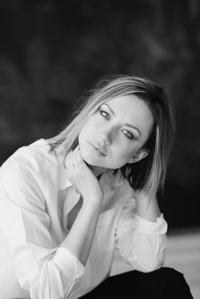

In [ ]:
from PIL import Image
import requests
from io import BytesIO

url = "https://raw.githubusercontent.com/febse/data/refs/heads/main/ta/example_photo.jpg"
response = requests.get(url)
img = Image.open(BytesIO(response.content)).convert("L")
img = img.resize((200, int(img.height * 200 / img.width)))
display(img)

In [ ]:
img_matrix = np.array(img)
print("Image matrix shape:", img_matrix.shape)

U_img, S_img, VT_img = np.linalg.svd(img_matrix, full_matrices=False)
print("U:", U_img.shape, " S:", S_img.shape, " V^T:", VT_img.shape)

Image matrix shape: (299, 200)
U: (299, 200)  S: (200,)  V^T: (200, 200)


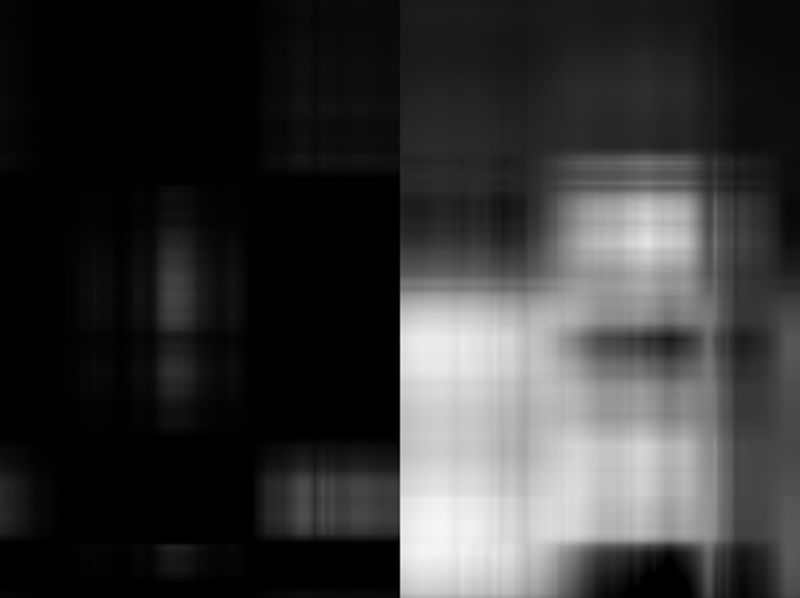

In [ ]:
# Left: the single layer number k. Right: the sum of the layers before k
layer_number = 2

display(show_reconstructed_image(layer_number, U_img, S_img, VT_img))

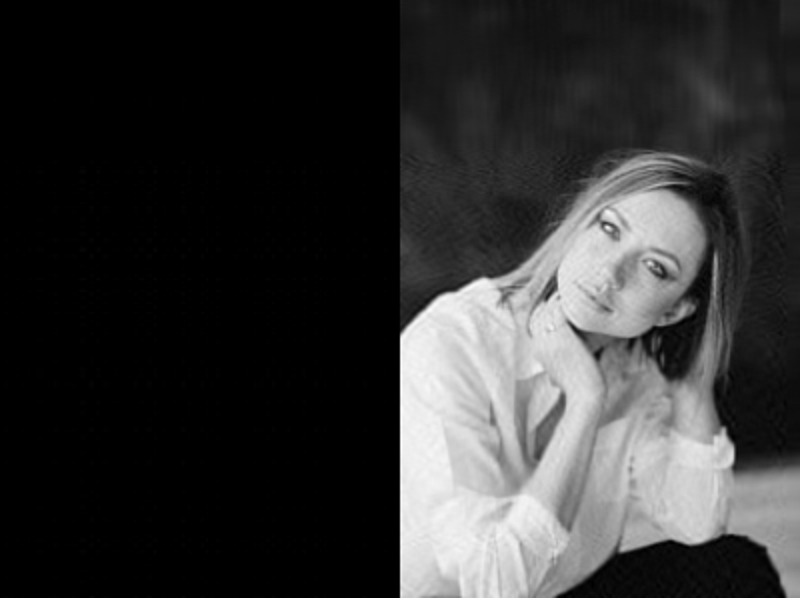

In [ ]:
layer_number = 50

display(show_reconstructed_image(layer_number, U_img, S_img, VT_img))

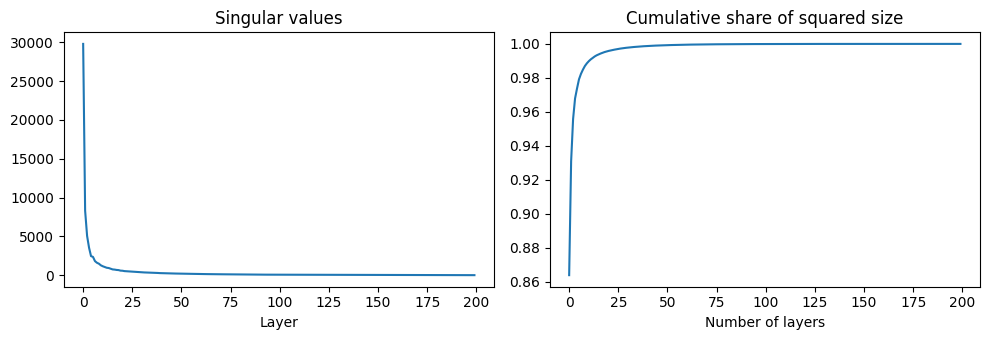

In [ ]:
# The singular values drop quickly: a few layers carry most of the picture
energy = np.cumsum(S_img**2) / np.sum(S_img**2)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(S_img)
axes[0].set_title("Singular values")
axes[0].set_xlabel("Layer")
axes[1].plot(energy)
axes[1].set_title("Cumulative share of squared size")
axes[1].set_xlabel("Number of layers")
plt.tight_layout()
plt.show()

**Approximation note (Eckart–Young).** For any $k \le r$, the truncated sum $X_k = \sum_{j=1}^{k} \sigma_j u_j v_j^\top$ is the best rank-$k$ approximation of $X$ in the Frobenius norm (and the spectral norm):

$$
\lVert X - X_k \rVert_F^2 = \sum_{j=k+1}^{r} \sigma_j^2 .
$$

The statement holds for every real matrix; it says nothing about whether a small $k$ is *good enough*: that depends on how quickly the singular values decay.

In [ ]:
# Check the error formula on the image
k = 20
image_approximation = U_img[:, :k] @ np.diag(S_img[:k]) @ VT_img[:k, :]

print("Actual squared error: ", np.linalg.norm(img_matrix - image_approximation) ** 2)
print("Sum of dropped sigma^2:", np.sum(S_img[k:] ** 2))

Actual squared error:  4597216.765009652
Sum of dropped sigma^2: 4597216.765009652


## Summary and next step

- $X^\top X$ ($m \times m$) has eigenvectors $v_j$: the **word** directions (right singular vectors).
- $XX^\top$ ($n \times n$) has eigenvectors $u_j$: the **document** directions (left singular vectors).
- Both have the same non-zero eigenvalues $\sigma_j^2$, and $X v_j = \sigma_j u_j$.
- $X = \sum_j \sigma_j u_j v_j^\top$: keeping only the first $k$ layers gives the best rank-$k$ approximation.

In the next notebook (Latent Semantic Analysis) we keep only the first $k$ layers of a TF-IDF matrix, so that documents and words are represented by $k$ numbers instead of $n$ or $m$.